# Trabajo Práctico 3 (TP3): Clasificación de Imágenes de Cáncer de Mama usando PCA y SVD

## Objetivo
El objetivo de este Trabajo Práctico es aplicar los conceptos de reducción de dimensionalidad vistos en la Clase 8 (**SVD y PCA**) para construir un clasificador de imágenes médicas. 

Trabajaremos con imágenes de ultrasonido de mama para clasificarlas en **Benignas** o **Malignas**.

## 1. Obtención del Dataset (BreastMNIST)
Para este TP utilizaremos **BreastMNIST**, un subconjunto del famoso dataset MedMNIST, el cual contiene imágenes de ultrasonido de mama de 28x28 píxeles en escala de grises.

**Instrucciones:** Si no tienes instalada la librería `medmnist`, ejecuta la siguiente celda.

In [1]:
%pip install medmnist

Note: you may need to restart the kernel to use updated packages.


A continuación, descargaremos y cargaremos los datos de entrenamiento y prueba.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import medmnist

from medmnist.dataset import BreastMNIST

# Descargar y cargar los datos
train_dataset = BreastMNIST(split='train', download=True)
test_dataset = BreastMNIST(split='test', download=True)

# Extraer las imágenes y las etiquetas
X_train = train_dataset.imgs
y_train = train_dataset.labels.squeeze()

X_test = test_dataset.imgs
y_test = test_dataset.labels.squeeze()

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

100%|██████████| 560k/560k [00:01<00:00, 298kB/s]  

Dimensiones de X_train: (546, 28, 28)
Dimensiones de X_test: (156, 28, 28)


### Consigna 1: Visualización Exploratoria
Extrae y visualiza al menos 3 imágenes correspondientes a tumores benignos (etiqueta 0) y 3 imágenes a tumores malignos (etiqueta 1).
¿Notas alguna diferencia visual obvia entre ambas clases?

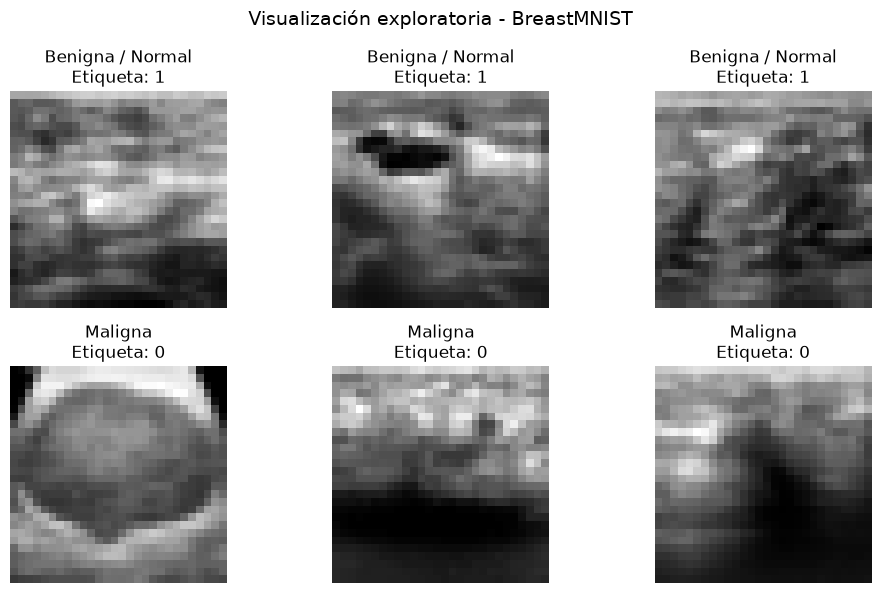

In [5]:
# TODO: Escribe tu código de visualización aquí
benigno_I = np.where(y_train == 1)[0]
maligno_I = np.where(y_train == 0)[0]

benigno_S = benigno_I[:3]
maligno_S = maligno_I[:3]

# Crear figura
fig, axes = plt.subplots(2, 3, figsize=(10, 6))

# Visualizar imágenes benignas / normales
for i, idx in enumerate(benigno_S):
    axes[0, i].imshow(X_train[idx], cmap='gray')
    axes[0, i].set_title(f'Benigna / Normal\nEtiqueta: 1')
    axes[0, i].axis('off')

# Visualizar imágenes malignas
for i, idx in enumerate(maligno_S):
    axes[1, i].imshow(X_train[idx], cmap='gray')
    axes[1, i].set_title(f'Maligna\nEtiqueta: 0')
    axes[1, i].axis('off')

plt.suptitle('Visualización exploratoria - BreastMNIST', fontsize=14)
plt.tight_layout()
plt.show()

## 2. Preprocesamiento y Vectorización
Para aplicar PCA o SVD estándar, necesitamos que cada imagen (una matriz 2D de 28x28) se convierta en un vector 1D (784 píxeles).

### Consigna 2: Vectorización y Centrado
1. Transforma `X_train` y `X_test` de dimensiones `(N, 28, 28)` a `(N, 784)`.
2. Calcula el **rostro (imagen) medio** del conjunto de entrenamiento y réstalo a todas las imágenes (tanto de train como de test) para centrar los datos.

X_train: (546, 784)
X_test: (156, 784)

Dimensiones después del centrado:
X_train: (546, 784)
X_test: (156, 784)

Media de los datos de entrenamiento: -0.0


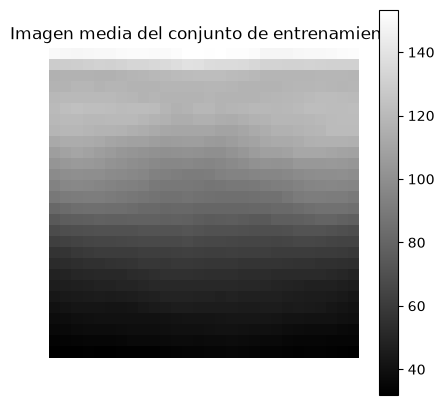

In [6]:
# TODO: Escribe tu código de preprocesamiento y centrado aquí
X_train = X_train.reshape(X_train.shape[0], -1).astype(np.float32)
X_test = X_test.reshape(X_test.shape[0], -1).astype(np.float32)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


mean_image = np.mean(X_train, axis=0)
mean_image_2d = mean_image.reshape(28, 28)

X_train = X_train - mean_image
X_test = X_test - mean_image


print("\nDimensiones después del centrado:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nMedia de los datos de entrenamiento:",
      np.mean(X_train).round(6))
plt.figure(figsize=(5, 5))
plt.imshow(mean_image_2d, cmap='gray')
plt.title("Imagen media del conjunto de entrenamiento")
plt.colorbar()
plt.axis('off')
plt.show()

## 3. Reducción de Dimensionalidad con SVD / PCA
Ahora aplicaremos SVD a nuestra matriz de datos centrados para extraer los **Componentes Principales** (las "Eigen-imágenes").

### Consigna 3: Cálculo de SVD
1. Aplica SVD a la matriz de entrenamiento centrada para obtener `U`, `S` y `V^T`.
2. Grafica la varianza explicada acumulada y decide un valor de `r` (número de componentes) que conserve al menos el 90% de la energía/varianza.
3. Visualiza los primeros 5 componentes principales (Eigen-imágenes) redimensionándolos de nuevo a 28x28.

Dimensiones de U: (546, 546)
Dimensiones de S: (546,)
Dimensiones de VT: (546, 784)
Número de componentes para conservar al menos el 90%: 36
Varianza explicada acumulada: 90.11%


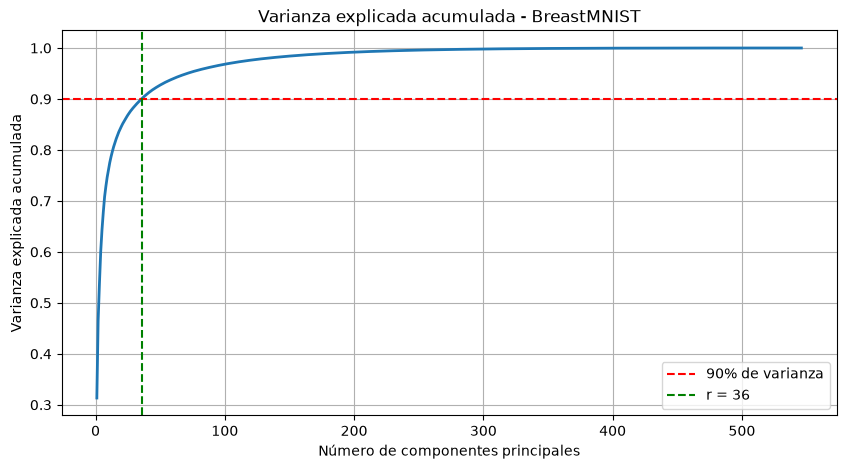

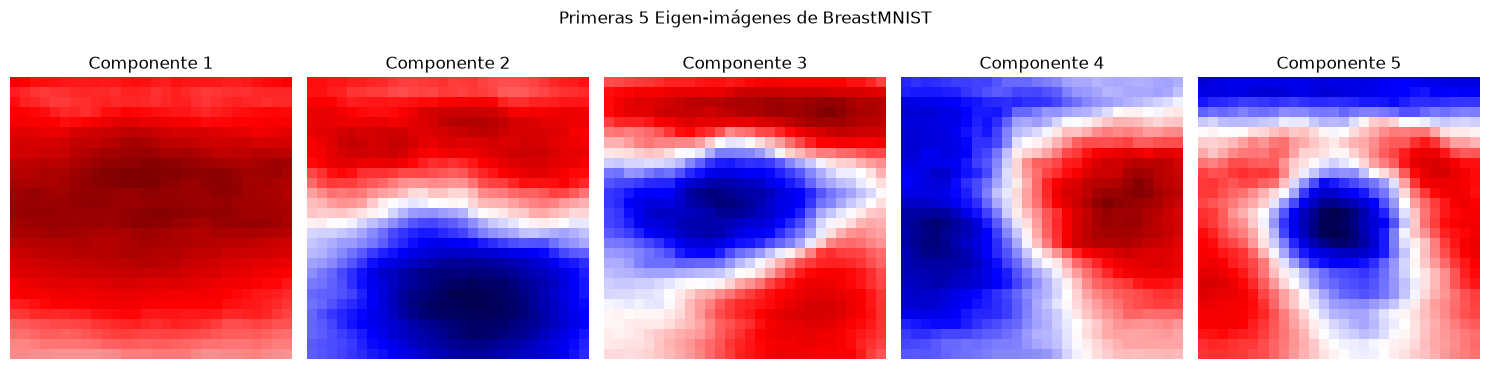

In [7]:
# TODO: Escribe tu código de SVD y visualización aquí
U, S, VT = np.linalg.svd(X_train, full_matrices=False)

print("Dimensiones de U:", U.shape)
print("Dimensiones de S:", S.shape)
print("Dimensiones de VT:", VT.shape)

explained_variance = (S ** 2) / (X_train.shape[0] - 1)
explained_variance_ratio = explained_variance / np.sum(explained_variance)
cumulative_variance = np.cumsum(explained_variance_ratio)

r = np.searchsorted(cumulative_variance, 0.90) + 1
print(f"Número de componentes para conservar al menos el 90%: {r}")
print(f"Varianza explicada acumulada: {cumulative_variance[r-1]*100:.2f}%")
plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2
)
plt.axhline(
    y=0.90,
    color='red',
    linestyle='--',
    label='90% de varianza'
)
plt.axvline(
    x=r,
    color='green',
    linestyle='--',
    label=f'r = {r}'
)
plt.xlabel('Número de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.title('Varianza explicada acumulada - BreastMNIST')

plt.legend()
plt.grid(True)
plt.show()
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for i in range(5):
    eigenimage = VT[i].reshape(28, 28)
    limit = np.max(np.abs(eigenimage))
    axes[i].imshow(
        eigenimage,
        cmap='seismic',
        vmin=-limit,
        vmax=limit
    )

    axes[i].set_title(f'Componente {i+1}')
    axes[i].axis('off')
plt.suptitle('Primeras 5 Eigen-imágenes de BreastMNIST')
plt.tight_layout()
plt.show()

## 4. Proyección y Clasificación
Una vez que tenemos la matriz de proyección (los primeros `r` componentes de `V^T` o equivalentemente usando Scikit-Learn `PCA`), proyectaremos los datos a un espacio de menor dimensión.

### Consigna 4: Clasificador Predictivo
1. Proyecta `X_train_centrado` y `X_test_centrado` sobre los primeros `r` componentes principales.
2. Entrena un clasificador simple, como **Regresión Logística** o **k-Nearest Neighbors (k-NN)**, usando las proyecciones de entrenamiento.
3. Evalúa el modelo en el conjunto de prueba usando `accuracy_score` y `classification_report`.
4. Prueba variar el número de componentes `r` (ej: 5, 20, 50) y describe cómo afecta el rendimiento.


Componentes: 5
Accuracy: 0.8013 (80.13%)

Componentes: 20
Accuracy: 0.8013 (80.13%)

Componentes: 36
Accuracy: 0.7949 (79.49%)

Componentes: 50
Accuracy: 0.7949 (79.49%)
Reporte de clasificacion con r = 36
              precision    recall  f1-score   support

           0       0.71      0.40      0.52        42
           1       0.81      0.94      0.87       114

    accuracy                           0.79       156
   macro avg       0.76      0.67      0.69       156
weighted avg       0.78      0.79      0.77       156



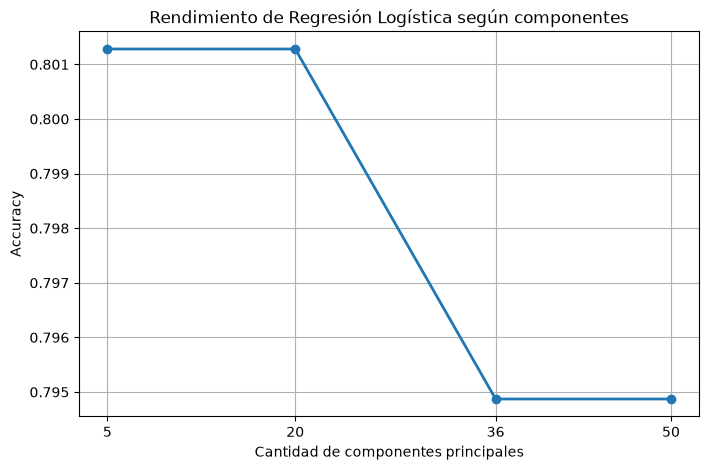

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# TODO: Escribe tu código de clasificación aquí

y_train = y_train.ravel()
y_test = y_test.ravel()

component_counts = sorted(set([5, 20, 50, r]))
results = {}
models = {}
for n in component_counts:
    components = VT[:n, :]
    X_train_pca = X_train @ components.T
    X_test_pca = X_test @ components.T
    model = LogisticRegression(max_iter=5000, random_state=42)
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    accuracy = accuracy_score(y_test, y_pred)
    results[n] = accuracy
    models[n] = model
    print(f"\nComponentes: {n}")
    print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")


print(f"Reporte de clasificacion con r = {r}")
components = VT[:r, :]
X_train_pca = X_train @ components.T
X_test_pca = X_test @ components.T
final_model = models[r]
y_pred = final_model.predict(X_test_pca)
print(classification_report(y_test, y_pred, zero_division=0))
plt.figure(figsize=(8, 5))
plt.plot(
    list(results.keys()),
    list(results.values()),
    marker='o',
    linewidth=2
)
plt.xlabel("Cantidad de componentes principales")
plt.ylabel("Accuracy")
plt.title("Rendimiento de Regresión Logística según componentes")
plt.xticks(list(results.keys()))
plt.grid(True)
plt.show()

### Consigna Opcional (Bonus)
Implementa un clasificador que, en lugar de usar un modelo externo como Regresión Logística, utilice directamente la reconstrucción de PCA. Por ejemplo, midiendo el error de reconstrucción de una imagen de prueba usando los componentes calculados únicamente sobre imágenes benignas vs imágenes malignas.